# 3. Tracking Baseline

We first use ground-truth masks to study tracking independently of
segmentation errors. Cell associations will be estimated from centroid
distances and mask overlap, without using reference track identities.

## 3.1 Extracting Cell Features

We inspect consecutive frames 50 and 51 before introducing division
handling. For each cell, we extract its centroid and area. Reference
IDs are retained only for subsequent evaluation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import tifffile

data_dir = Path("../data/ctc_format")

frame_a, frame_b = 50, 51

mask_a = tifffile.imread(
    data_dir / f"00_GT/TRA/man_track{frame_a:04d}.tif"
)
mask_b = tifffile.imread(
    data_dir / f"00_GT/TRA/man_track{frame_b:04d}.tif"
)


def extract_cell_features(mask):
    records = []

    for cell_id in np.unique(mask):
        if cell_id == 0:
            continue

        rows, cols = np.where(mask == cell_id)

        records.append({
            "reference_id": int(cell_id),
            "center_x": cols.mean(),
            "center_y": rows.mean(),
            "area_pixels": len(rows),
        })

    return pd.DataFrame(
        records,
        columns=["reference_id", "center_x", "center_y", "area_pixels"],
    )


cells_a = extract_cell_features(mask_a)
cells_b = extract_cell_features(mask_b)

print(f"Frame {frame_a}")
display(cells_a.round(2))

print(f"Frame {frame_b}")
display(cells_b.round(2))

Frame 50


,reference_id,center_x,center_y,area_pixels
0,23,523.03,423.08,633
1,2102,486.79,422.24,676


Frame 51


,reference_id,center_x,center_y,area_pixels
0,23,523.57,424.47,629
1,2102,487.16,423.53,691


## 3.2 Matching Cells Between Consecutive Frames

We combine normalized centroid distance and mask IoU with equal
weights. Hungarian assignment selects one-to-one associations.
Dummy assignments allow cells to remain unmatched.

A maximum displacement of 20 pixels is an exploratory setting that
requires validation. Reference IDs are used only after matching to
check continuation links.

In [5]:
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment

max_distance = 20.0

# Compute geometric features without comparing reference identities.
positions_a = cells_a[["center_x", "center_y"]].to_numpy()
positions_b = cells_b[["center_x", "center_y"]].to_numpy()

distances = cdist(positions_a, positions_b)
overlaps = np.zeros_like(distances)

for i, id_a in enumerate(cells_a["reference_id"]):
    object_a = mask_a == id_a

    for j, id_b in enumerate(cells_b["reference_id"]):
        object_b = mask_b == id_b
        intersection = np.count_nonzero(object_a & object_b)
        union = np.count_nonzero(object_a | object_b)
        overlaps[i, j] = intersection / union

cost = 0.5 * (distances / max_distance) + 0.5 * (1 - overlaps)

# Add dummy rows and columns for unmatched cells.
n, m = cost.shape
assignment_cost = np.full((n + m, n + m), 1e6)
assignment_cost[:n, :m] = np.where(
    distances <= max_distance, cost, 1e6
)

unmatched_cost = 0.5
assignment_cost[np.arange(n), m + np.arange(n)] = unmatched_cost
assignment_cost[n + np.arange(m), np.arange(m)] = unmatched_cost
assignment_cost[n:, m:] = 0

rows, cols = linear_sum_assignment(assignment_cost)

links = []

for i, j in zip(rows, cols):
    if i < n and j < m and assignment_cost[i, j] < 1e6:
        id_a = int(cells_a.iloc[i]["reference_id"])
        id_b = int(cells_b.iloc[j]["reference_id"])

        links.append({
            "source_reference_id": id_a,
            "target_reference_id": id_b,
            "distance_pixels": distances[i, j],
            "IoU": overlaps[i, j],
            "cost": cost[i, j],
            # Valid for checking continuation links on this frame pair.
            "correct_continuation": id_a == id_b,
        })

links = pd.DataFrame(links)
display(links.round(3))

,source_reference_id,target_reference_id,distance_pixels,IoU,cost,correct_continuation
0,23,23,0.467,0.945,0.039,True
1,2102,2103,9.170,0.434,0.512,False


## 3.3 Testing the Baseline at a Division Event

The baseline correctly matched both continuation links between
frames 50 and 51. We now apply the same method to frames 51 and 52,
where reference track 2102 divides into tracks 2103 and 3716.

One-to-one assignment cannot represent both daughter links.
This experiment illustrates why explicit division handling is needed.

In [3]:
# Preserve the previous result.
continuation_links = links.copy()

# Load the frames surrounding the annotated division.
frame_a, frame_b = 51, 52

mask_a = tifffile.imread(
    data_dir / f"00_GT/TRA/man_track{frame_a:04d}.tif"
)
mask_b = tifffile.imread(
    data_dir / f"00_GT/TRA/man_track{frame_b:04d}.tif"
)

cells_a = extract_cell_features(mask_a)
cells_b = extract_cell_features(mask_b)

print(f"Frame {frame_a}")
display(cells_a.round(2))

print(f"Frame {frame_b}")
display(cells_b.round(2))

Frame 51


,reference_id,center_x,center_y,area_pixels
0,23,523.57,424.47,629
1,2102,487.16,423.53,691


Frame 52


,reference_id,center_x,center_y,area_pixels
0,23,523.53,424.00,641
1,2103,480.09,429.37,459
2,3716,496.35,412.68,302


## 3.4 Generating Division Candidates

The one-to-one baseline links parent 2102 to only one daughter.
We now search for pairs of nearby cells whose combined area is
consistent with a possible parent.

Both daughters must be smaller than the parent. All thresholds
are exploratory. Reference lineage relationships are not used
to generate candidates.

In [6]:
from itertools import combinations

division_candidates = []

for i, parent in cells_a.iterrows():
    nearby = np.flatnonzero(distances[i] <= max_distance)

    for j, k in combinations(nearby, 2):
        daughter_a = cells_b.iloc[j]
        daughter_b = cells_b.iloc[k]

        parent_area = parent["area_pixels"]
        area_a = daughter_a["area_pixels"]
        area_b = daughter_b["area_pixels"]
        combined_ratio = (area_a + area_b) / parent_area

        if (
            area_a < 0.85 * parent_area
            and area_b < 0.85 * parent_area
            and 0.7 <= combined_ratio <= 1.3
        ):
            division_candidates.append({
                "parent_reference_id": int(parent["reference_id"]),
                "daughter_a_reference_id": int(daughter_a["reference_id"]),
                "daughter_b_reference_id": int(daughter_b["reference_id"]),
                "combined_area_ratio": combined_ratio,
            })

division_candidates = pd.DataFrame(
    division_candidates,
    columns=[
        "parent_reference_id",
        "daughter_a_reference_id",
        "daughter_b_reference_id",
        "combined_area_ratio",
    ],
)

display(division_candidates.round(3))

,parent_reference_id,daughter_a_reference_id,daughter_b_reference_id,combined_area_ratio
0,2102,2103,3716,1.101


## 3.5 Checking the Division Candidate Against Ground Truth

We compare the proposed parent–daughter pair with the reference
lineage table. A candidate is correct only if both daughters have
the proposed parent, start in the target frame, and the parent
ends in the source frame.

Reference lineage records are used only for evaluation.

In [7]:
lineage = pd.read_csv(
    data_dir / "00_GT/TRA/man_track.txt",
    sep=r"\s+",
    header=None,
    names=["track_id", "start_frame", "end_frame", "parent_id"],
)

reference_tracks = lineage.set_index("track_id")
checked_candidates = division_candidates.copy()

checks = []

for candidate in division_candidates.itertuples(index=False):
    parent_id = candidate.parent_reference_id
    daughter_ids = [
        candidate.daughter_a_reference_id,
        candidate.daughter_b_reference_id,
    ]

    parent = reference_tracks.loc[parent_id]
    daughters = reference_tracks.loc[daughter_ids]

    correct = (
        parent["end_frame"] == frame_a
        and (daughters["parent_id"] == parent_id).all()
        and (daughters["start_frame"] == frame_b).all()
    )
    checks.append(bool(correct))

checked_candidates["correct_division"] = checks
display(checked_candidates.round(3))

,parent_reference_id,daughter_a_reference_id,daughter_b_reference_id,combined_area_ratio,correct_division
0,2102,2103,3716,1.101,True


## 3.6 Integrating Division Candidates

We prioritize division candidates whose combined daughter area is
closest to the parent area. Candidates cannot share a parent or daughter.
Accepted divisions replace conflicting one-to-one assignments.

This greedy rule is exploratory. Ground-truth correctness flags are
not used for selection.

In [8]:
# Preserve the one-to-one baseline.
baseline_links = links.copy()

candidates = division_candidates.copy()
candidates["area_deviation"] = abs(
    candidates["combined_area_ratio"] - 1.0
)

used_parents = set()
used_daughters = set()
division_edges = []

for candidate in candidates.sort_values("area_deviation").itertuples():
    parent = int(candidate.parent_reference_id)
    daughters = [
        int(candidate.daughter_a_reference_id),
        int(candidate.daughter_b_reference_id),
    ]

    if parent in used_parents or any(
        daughter in used_daughters for daughter in daughters
    ):
        continue

    used_parents.add(parent)
    used_daughters.update(daughters)

    for daughter in daughters:
        division_edges.append({
            "source_reference_id": parent,
            "target_reference_id": daughter,
            "event": "division",
        })

# Remove baseline links that conflict with accepted divisions.
remaining_links = baseline_links[
    ~baseline_links["source_reference_id"].isin(used_parents)
    & ~baseline_links["target_reference_id"].isin(used_daughters)
][["source_reference_id", "target_reference_id"]].copy()

remaining_links["event"] = "continuation"

division_aware_links = pd.concat(
    [
        remaining_links,
        pd.DataFrame(
            division_edges,
            columns=["source_reference_id", "target_reference_id", "event"],
        ),
    ],
    ignore_index=True,
)

display(division_aware_links)

,source_reference_id,target_reference_id,event
0,23,23,continuation
1,2102,2103,division
2,2102,3716,division


## 3.7 Evaluating Links for the Division Transition

We construct reference edges from persistent track identities and
annotated parent–daughter relationships for frames 51–52.

Link F1 evaluates individual edges, including division edges.
It does not evaluate complete division events or full trajectories.
This is a single-transition development check.

In [9]:
assert (frame_a, frame_b) == (51, 52)

source_ids = set(cells_a["reference_id"].astype(int))
target_ids = set(cells_b["reference_id"].astype(int))

# Continuation edges: the same reference track appears in both frames.
reference_edges = {
    (cell_id, cell_id)
    for cell_id in source_ids & target_ids
}

# Division edges: a daughter starts immediately after its parent ends.
for track in lineage.itertuples(index=False):
    parent_id = int(track.parent_id)
    daughter_id = int(track.track_id)

    if (
        parent_id in source_ids
        and daughter_id in target_ids
        and track.start_frame == frame_b
        and reference_tracks.loc[parent_id, "end_frame"] == frame_a
    ):
        reference_edges.add((parent_id, daughter_id))


def evaluate_links(link_table, reference_edges):
    predicted_edges = set(
        link_table[
            ["source_reference_id", "target_reference_id"]
        ].itertuples(index=False, name=None)
    )

    tp = len(predicted_edges & reference_edges)
    fp = len(predicted_edges - reference_edges)
    fn = len(reference_edges - predicted_edges)

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": tp / (tp + fp) if tp + fp else 0.0,
        "Recall": tp / (tp + fn) if tp + fn else 0.0,
        "Link_F1": 2 * tp / (2 * tp + fp + fn)
        if 2 * tp + fp + fn else 0.0,
    }


tracking_comparison = pd.DataFrame([
    {
        "Method": "Hungarian baseline",
        **evaluate_links(baseline_links, reference_edges),
    },
    {
        "Method": "Division-aware baseline",
        **evaluate_links(division_aware_links, reference_edges),
    },
])

display(tracking_comparison.round(3))

,Method,TP,FP,FN,Precision,Recall,Link_F1
0,Hungarian baseline,2,0,1,1.0,0.667,0.8
1,Division-aware baseline,3,0,0,1.0,1.000,1.0


## 3.8 Evaluating Complete Division Events

A division is correct only when the parent and both daughters match
the reference event at this frame transition. Daughter order does
not matter. The Hungarian baseline predicts no explicit divisions.

These results concern one development transition with ground-truth
masks, not overall tracking performance.

In [10]:
def extract_division_events(link_table):
    events = set()

    for parent, group in link_table.groupby("source_reference_id"):
        daughters = set(group["target_reference_id"].astype(int))

        if len(daughters) == 2:
            events.add((int(parent), tuple(sorted(daughters))))

    return events


# Reference divisions are parent-to-two-daughter edges.
reference_edge_table = pd.DataFrame(
    sorted(reference_edges),
    columns=["source_reference_id", "target_reference_id"],
)

reference_divisions = extract_division_events(reference_edge_table)

# The baseline has no division-detection mechanism.
baseline_divisions = set()

predicted_divisions = extract_division_events(
    division_aware_links[
        division_aware_links["event"] == "division"
    ]
)


def evaluate_divisions(predicted, reference):
    tp = len(predicted & reference)
    fp = len(predicted - reference)
    fn = len(reference - predicted)

    return {
        "Division_TP": tp,
        "Division_FP": fp,
        "Division_FN": fn,
        "Division_F1": (
            2 * tp / (2 * tp + fp + fn)
            if 2 * tp + fp + fn else np.nan
        ),
    }


division_comparison = pd.DataFrame([
    {
        "Method": "Hungarian baseline",
        **evaluate_divisions(baseline_divisions, reference_divisions),
    },
    {
        "Method": "Division-aware baseline",
        **evaluate_divisions(predicted_divisions, reference_divisions),
    },
])

display(division_comparison.round(3))

,Method,Division_TP,Division_FP,Division_FN,Division_F1
0,Hungarian baseline,0,0,1,0.0
1,Division-aware baseline,1,0,0,1.0


### Single-Transition Findings

For sequence 00, frames 51–52, adding division handling increased
link F1 from 0.800 to 1.000 and detected the single reference
division event (division F1 = 1.000).

These results use ground-truth masks and one inspected development
transition. Broader evaluation is needed to measure false divisions,
missed divisions, and performance in dense populations.

In [11]:
results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

tracking_comparison.to_csv(
    results_dir / "tracking_seq00_0051_0052.csv", index=False
)
division_comparison.to_csv(
    results_dir / "division_seq00_0051_0052.csv", index=False
)
division_aware_links.to_csv(
    results_dir / "links_seq00_0051_0052.csv", index=False
)

print("Tracking results saved.")

Tracking results saved.


## 3.9 Reusable Frame-Pair Tracker

We package the existing Hungarian baseline and exploratory division
rules into one function. The function receives two masks and returns
baseline and division-aware links.

Reference identities and lineage records are not compared during
association. Mask labels serve only as object identifiers.

In [12]:
from itertools import combinations
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment


def track_frame_pair(mask_a, mask_b, max_distance=20.0):
    """Return baseline and division-aware links for two masks."""
    cells_a = extract_cell_features(mask_a)
    cells_b = extract_cell_features(mask_b)

    columns = [
        "source_reference_id", "target_reference_id", "event"
    ]
    n, m = len(cells_a), len(cells_b)

    if n == 0 or m == 0:
        empty = pd.DataFrame(columns=columns)
        return empty.copy(), empty.copy()

    positions_a = cells_a[["center_x", "center_y"]].to_numpy()
    positions_b = cells_b[["center_x", "center_y"]].to_numpy()
    distances = cdist(positions_a, positions_b)

    ids_a = cells_a["reference_id"].to_numpy(dtype=int)
    ids_b = cells_b["reference_id"].to_numpy(dtype=int)
    areas_a = cells_a["area_pixels"].to_numpy()
    areas_b = cells_b["area_pixels"].to_numpy()

    overlaps = np.zeros((n, m))

    for i, id_a in enumerate(ids_a):
        object_a = mask_a == id_a

        for j in np.flatnonzero(distances[i] <= max_distance):
            object_b = mask_b == ids_b[j]
            intersection = np.count_nonzero(object_a & object_b)
            union = areas_a[i] + areas_b[j] - intersection
            overlaps[i, j] = intersection / union

    # One-to-one matching with unmatched-cell options.
    cost = (
        0.5 * distances / max_distance
        + 0.5 * (1 - overlaps)
    )

    assignment_cost = np.full((n + m, n + m), 1e6)
    assignment_cost[:n, :m] = np.where(
        distances <= max_distance, cost, 1e6
    )
    assignment_cost[np.arange(n), m + np.arange(n)] = 0.5
    assignment_cost[n + np.arange(m), np.arange(m)] = 0.5
    assignment_cost[n:, m:] = 0

    rows, cols = linear_sum_assignment(assignment_cost)

    baseline_records = [
        (int(ids_a[i]), int(ids_b[j]), "continuation")
        for i, j in zip(rows, cols)
        if i < n and j < m and assignment_cost[i, j] < 1e6
    ]

    baseline = pd.DataFrame(baseline_records, columns=columns)

    # Generate division candidates using geometry and area only.
    candidates = []

    for i in range(n):
        nearby = np.flatnonzero(distances[i] <= max_distance)

        for j, k in combinations(nearby, 2):
            ratio = (areas_b[j] + areas_b[k]) / areas_a[i]

            if (
                areas_b[j] < 0.85 * areas_a[i]
                and areas_b[k] < 0.85 * areas_a[i]
                and 0.7 <= ratio <= 1.3
            ):
                candidates.append((abs(ratio - 1), i, j, k))

    used_parents = set()
    used_daughters = set()
    division_records = []

    for _, i, j, k in sorted(candidates):
        parent = int(ids_a[i])
        daughters = [int(ids_b[j]), int(ids_b[k])]

        if parent in used_parents or any(
            daughter in used_daughters for daughter in daughters
        ):
            continue

        used_parents.add(parent)
        used_daughters.update(daughters)

        division_records.extend(
            (parent, daughter, "division")
            for daughter in daughters
        )

    remaining = baseline[
        ~baseline["source_reference_id"].isin(used_parents)
        & ~baseline["target_reference_id"].isin(used_daughters)
    ]

    improved = pd.concat(
        [
            remaining,
            pd.DataFrame(division_records, columns=columns),
        ],
        ignore_index=True,
    )

    return baseline, improved

In [13]:
# Reload explicitly so this check does not depend on earlier frame variables.
check_mask_a = tifffile.imread(
    data_dir / "00_GT/TRA/man_track0051.tif"
)
check_mask_b = tifffile.imread(
    data_dir / "00_GT/TRA/man_track0052.tif"
)

check_baseline, check_improved = track_frame_pair(
    check_mask_a, check_mask_b
)

print("Hungarian baseline: frames 51–52")
display(check_baseline)

print("Division-aware baseline: frames 51–52")
display(check_improved)

Hungarian baseline: frames 51–52


,source_reference_id,target_reference_id,event
0,23,23,continuation
1,2102,2103,continuation


Division-aware baseline: frames 51–52


,source_reference_id,target_reference_id,event
0,23,23,continuation
1,2102,2103,division
2,2102,3716,division


## 3.10 Evaluation Across Development Transitions

We evaluate both methods on five consecutive-frame transitions
using ground-truth masks. Tracker settings remain unchanged.

Reference edges and complete division events are derived separately
from the lineage annotations. Division F1 is undefined (NaN) when
neither reference nor predicted divisions exist.

In [14]:
def get_reference_events(mask_a, mask_b, frame_a, lineage):
    """Build reference edges and division events for consecutive frames."""
    source_ids = set(np.unique(mask_a)) - {0}
    target_ids = set(np.unique(mask_b)) - {0}

    edges = {
        (int(cell_id), int(cell_id))
        for cell_id in source_ids & target_ids
    }

    parent_end_frames = lineage.set_index("track_id")["end_frame"]
    daughters_by_parent = {}

    for track in lineage.itertuples(index=False):
        parent = int(track.parent_id)
        daughter = int(track.track_id)

        if (
            parent in source_ids
            and daughter in target_ids
            and track.start_frame == frame_a + 1
            and parent_end_frames.get(parent) == frame_a
        ):
            edges.add((parent, daughter))
            daughters_by_parent.setdefault(parent, set()).add(daughter)

    divisions = {
        (parent, tuple(sorted(daughters)))
        for parent, daughters in daughters_by_parent.items()
        if len(daughters) == 2
    }

    return edges, divisions


development_frames = [50, 51, 73, 399, 599]
records = []

for frame in development_frames:
    source_mask = tifffile.imread(
        data_dir / f"00_GT/TRA/man_track{frame:04d}.tif"
    )
    target_mask = tifffile.imread(
        data_dir / f"00_GT/TRA/man_track{frame + 1:04d}.tif"
    )

    baseline, improved = track_frame_pair(source_mask, target_mask)

    reference_edges, reference_divisions = get_reference_events(
        source_mask, target_mask, frame, lineage
    )

    for name, predicted_links in [
        ("Hungarian", baseline),
        ("Division-aware", improved),
    ]:
        predicted_divisions = extract_division_events(
            predicted_links[predicted_links["event"] == "division"]
        )

        records.append({
            "Transition": f"{frame}→{frame + 1}",
            "Method": name,
            **evaluate_links(predicted_links, reference_edges),
            **evaluate_divisions(
                predicted_divisions, reference_divisions
            ),
        })

development_results = pd.DataFrame(records)
display(development_results.round(3))

,Transition,Method,TP,FP,FN,Precision,Recall,Link_F1,Division_TP,Division_FP,Division_FN,Division_F1
0,50→51,Hungarian,2,0,0,1.000,1.000,1.000,0,0,0,NaN
1,50→51,Division-aware,2,0,0,1.000,1.000,1.000,0,0,0,NaN
2,51→52,Hungarian,2,0,1,1.000,0.667,0.800,0,0,1,0.000
3,51→52,Division-aware,3,0,0,1.000,1.000,1.000,1,0,0,1.000
4,73→74,Hungarian,3,0,1,1.000,0.750,0.857,0,0,1,0.000
5,73→74,Division-aware,4,0,0,1.000,1.000,1.000,1,0,0,1.000
6,399→400,Hungarian,57,0,1,1.000,0.983,0.991,0,0,1,0.000
7,399→400,Division-aware,58,0,0,1.000,1.000,1.000,1,0,0,1.000
8,599→600,Hungarian,392,0,4,1.000,0.990,0.995,0,0,4,0.000
9,599→600,Division-aware,387,6,9,0.985,0.977,0.981,4,3,0,0.727


### Findings Across Development Transitions

Division handling recovered all reference divisions in the inspected
transitions. However, at frames 599–600, it also introduced three false
division events. Link F1 decreased from 0.995 to 0.981, while division
F1 reached 0.727.

This demonstrates a limitation of proximity and area-based rules in
dense populations. Detecting more divisions does not necessarily
improve overall link accuracy.

In [15]:
# Reload the dense transition explicitly.
dense_frame = 599

dense_a = tifffile.imread(
    data_dir / "00_GT/TRA/man_track0599.tif"
)
dense_b = tifffile.imread(
    data_dir / "00_GT/TRA/man_track0600.tif"
)

dense_baseline, dense_improved = track_frame_pair(dense_a, dense_b)

_, dense_reference_divisions = get_reference_events(
    dense_a, dense_b, dense_frame, lineage
)

dense_predicted_divisions = extract_division_events(
    dense_improved[dense_improved["event"] == "division"]
)

false_divisions = (
    dense_predicted_divisions - dense_reference_divisions
)

false_division_table = pd.DataFrame(
    [
        {
            "parent_reference_id": parent,
            "daughter_a_reference_id": daughters[0],
            "daughter_b_reference_id": daughters[1],
        }
        for parent, daughters in sorted(false_divisions)
    ],
    columns=[
        "parent_reference_id",
        "daughter_a_reference_id",
        "daughter_b_reference_id",
    ],
)

display(false_division_table)

,parent_reference_id,daughter_a_reference_id,daughter_b_reference_id
0,1551,3341,3427
1,1663,915,1734
2,1832,970,1008


## 3.11 Visualizing a False Division

We inspect the first false division predicted at frames 599–600.
The proposed parent is highlighted in orange and the proposed
daughters in cyan and magenta.

Reference records are displayed to investigate why this proposed
event disagrees with the annotation.

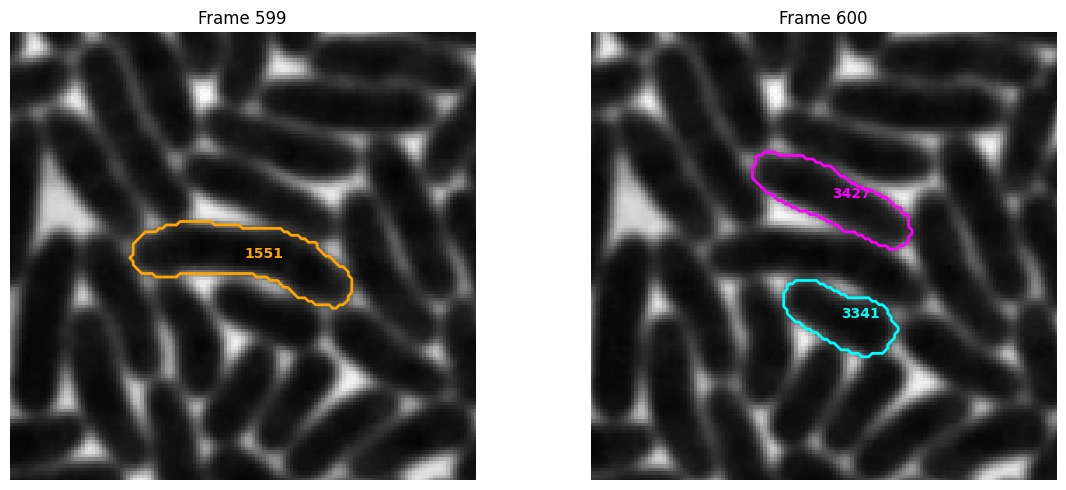

,track_id,start_frame,end_frame,parent_id
1550,1551,551,612,1543
3340,3341,587,663,3337
3426,3427,533,623,3426


In [16]:
import matplotlib.pyplot as plt

example = false_division_table.iloc[0]

parent_id = int(example["parent_reference_id"])
daughter_ids = [
    int(example["daughter_a_reference_id"]),
    int(example["daughter_b_reference_id"]),
]

# Use a shared crop containing all three selected objects.
selected_region = (
    (dense_a == parent_id)
    | np.isin(dense_b, daughter_ids)
)

rows, cols = np.where(selected_region)
padding = 35

y_min = max(0, rows.min() - padding)
y_max = min(dense_a.shape[0], rows.max() + padding + 1)
x_min = max(0, cols.min() - padding)
x_max = min(dense_a.shape[1], cols.max() + padding + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, frame, labels, ids, colors in [
    (axes[0], 599, dense_a, [parent_id], ["orange"]),
    (axes[1], 600, dense_b, daughter_ids, ["cyan", "magenta"]),
]:
    raw = tifffile.imread(data_dir / f"00/t{frame:04d}.tif")
    ax.imshow(raw, cmap="gray")

    for cell_id, color in zip(ids, colors):
        cell_mask = labels == cell_id
        ax.contour(
            cell_mask, levels=[0.5], colors=[color], linewidths=2
        )
        y, x = np.argwhere(cell_mask).mean(axis=0)
        ax.text(
            x, y, str(cell_id), color=color,
            fontsize=10, weight="bold"
        )

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_max, y_min)
    ax.set_title(f"Frame {frame}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# Inspect actual lifetimes and parent relationships.
display(
    lineage[
        lineage["track_id"].isin([parent_id] + daughter_ids)
    ].sort_values("track_id")
)

### Failure Analysis: False Division in a Dense Population

The tracker incorrectly proposed 1551 → {3341, 3427}.
Reference records show that track 1551 continues until frame 612,
while tracks 3341 and 3427 already exist before frame 600.

Proximity and combined area alone therefore cannot reliably distinguish
division from nearby independent cells. Prioritizing this candidate
also removes valid continuation links.

A planned improvement is to consider strong continuation evidence
before accepting a division, together with parent-to-daughter mask
overlap. These changes require validation on additional transitions.

## 3.12 Protecting Strong Continuation Links

We explore a continuation-protection rule. Hungarian links with
IoU ≥ 0.7 and a target/source area ratio between 0.8 and 1.2 are
protected. Division candidates involving these objects are rejected.

These exploratory thresholds require validation. Reference identities
are not compared, and lineage annotations are not used for selection.

In [17]:
def track_with_protection(mask_a, mask_b, max_distance=20.0):
    # Retrieve the original Hungarian assignments.
    baseline, _ = track_frame_pair(mask_a, mask_b, max_distance)

    protected_sources = set()
    protected_targets = set()

    for link in baseline.itertuples(index=False):
        source = int(link.source_reference_id)
        target = int(link.target_reference_id)

        source_mask = mask_a == source
        target_mask = mask_b == target

        source_area = np.count_nonzero(source_mask)
        target_area = np.count_nonzero(target_mask)

        intersection = np.count_nonzero(source_mask & target_mask)
        union = source_area + target_area - intersection

        overlap = intersection / union
        area_ratio = target_area / source_area

        if overlap >= 0.7 and 0.8 <= area_ratio <= 1.2:
            protected_sources.add(source)
            protected_targets.add(target)

    # Remove protected objects from division consideration.
    remaining_a = mask_a.copy()
    remaining_b = mask_b.copy()

    remaining_a[np.isin(mask_a, list(protected_sources))] = 0
    remaining_b[np.isin(mask_b, list(protected_targets))] = 0

    # Re-run association on the remaining objects.
    _, remaining_links = track_frame_pair(
        remaining_a, remaining_b, max_distance
    )

    protected_links = baseline[
        baseline["source_reference_id"].isin(protected_sources)
    ].copy()

    return pd.concat(
        [protected_links, remaining_links],
        ignore_index=True,
    )

In [18]:
protected_links = track_with_protection(dense_a, dense_b)

dense_reference_edges, dense_reference_divisions = get_reference_events(
    dense_a, dense_b, 599, lineage
)

records = []

for name, predicted_links in [
    ("Hungarian", dense_baseline),
    ("Original division rules", dense_improved),
    ("Continuation protection", protected_links),
]:
    predicted_events = extract_division_events(
        predicted_links[predicted_links["event"] == "division"]
    )

    records.append({
        "Method": name,
        **evaluate_links(predicted_links, dense_reference_edges),
        **evaluate_divisions(
            predicted_events, dense_reference_divisions
        ),
    })

protection_comparison = pd.DataFrame(records)
display(protection_comparison.round(3))

,Method,TP,FP,FN,Precision,Recall,Link_F1,Division_TP,Division_FP,Division_FN,Division_F1
0,Hungarian,392,0,4,1.000,0.990,0.995,0,0,4,0.000
1,Original division rules,387,6,9,0.985,0.977,0.981,4,3,0,0.727
2,Continuation protection,396,0,0,1.000,1.000,1.000,4,0,0,1.000


### Effect of Continuation Protection

On transition 599–600, continuation protection removed all three false
division events while retaining all four reference divisions.
Link F1 increased from 0.981 to 1.000, and division F1 increased
from 0.727 to 1.000.

The rule was developed after inspecting errors on this transition.
These results demonstrate a development improvement; generalization
must be assessed on separate data.

In [19]:
protection_comparison.to_csv(
    results_dir / "continuation_protection_seq00_0599_0600.csv",
    index=False,
)

## 3.13 Validation on a Separate Sequence

Sequence 00 was used for exploratory development. We now evaluate
fixed tracker settings on transitions 0–1, 199–200, 399–400,
599–600, and 798–799 of sequence 01, without selecting transitions
based on their outcomes.

We compare Hungarian assignment, the original division rules, and
continuation protection using ground-truth masks. Sequence 04 is
reserved for final testing. This sparse validation check does not
evaluate complete trajectories.

In [20]:
validation_sequence = "01"
validation_frames = [0, 199, 399, 599, 798]

validation_lineage = pd.read_csv(
    data_dir / f"{validation_sequence}_GT/TRA/man_track.txt",
    sep=r"\s+",
    header=None,
    names=["track_id", "start_frame", "end_frame", "parent_id"],
)

validation_records = []

for frame in validation_frames:
    source_mask = tifffile.imread(
        data_dir
        / f"{validation_sequence}_GT/TRA/man_track{frame:04d}.tif"
    )
    target_mask = tifffile.imread(
        data_dir
        / f"{validation_sequence}_GT/TRA/man_track{frame + 1:04d}.tif"
    )

    baseline, original_rules = track_frame_pair(
        source_mask, target_mask, max_distance=20.0
    )
    protected = track_with_protection(
        source_mask, target_mask, max_distance=20.0
    )

    reference_edges, reference_divisions = get_reference_events(
        source_mask, target_mask, frame, validation_lineage
    )

    for name, predicted_links in [
        ("Hungarian", baseline),
        ("Original division rules", original_rules),
        ("Continuation protection", protected),
    ]:
        predicted_divisions = extract_division_events(
            predicted_links[predicted_links["event"] == "division"]
        )

        validation_records.append({
            "Sequence": validation_sequence,
            "Transition": f"{frame}→{frame + 1}",
            "Method": name,
            "Reference_divisions": len(reference_divisions),
            **evaluate_links(predicted_links, reference_edges),
            **evaluate_divisions(
                predicted_divisions, reference_divisions
            ),
        })

    print(f"Completed transition {frame} → {frame + 1}")

validation_results = pd.DataFrame(validation_records)

results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

validation_results.to_csv(
    results_dir / "tracking_validation_seq01.csv",
    index=False,
)

display(validation_results.round(3))

Completed transition 0 → 1
Completed transition 199 → 200
Completed transition 399 → 400
Completed transition 599 → 600
Completed transition 798 → 799


,Sequence,Transition,Method,Reference_divisions,TP,FP,FN,Precision,Recall,Link_F1,Division_TP,Division_FP,Division_FN,Division_F1
0,01,0→1,Hungarian,0,2,0,0,1.000,1.000,1.000,0,0,0,NaN
1,01,0→1,Original division rules,0,2,0,0,1.000,1.000,1.000,0,0,0,NaN
2,01,0→1,Continuation protection,0,2,0,0,1.000,1.000,1.000,0,0,0,NaN
3,01,199→200,Hungarian,0,16,0,0,1.000,1.000,1.000,0,0,0,NaN
4,01,199→200,Original division rules,0,16,0,0,1.000,1.000,1.000,0,0,0,NaN
5,01,199→200,Continuation protection,0,16,0,0,1.000,1.000,1.000,0,0,0,NaN
6,01,399→400,Hungarian,3,76,0,3,1.000,0.962,0.981,0,0,3,0.000
7,01,399→400,Original division rules,3,79,0,0,1.000,1.000,1.000,3,0,0,1.000
8,01,399→400,Continuation protection,3,79,0,0,1.000,1.000,1.000,3,0,0,1.000
9,01,599→600,Hungarian,7,550,0,7,1.000,0.987,0.994,0,0,7,0.000


## 3.14 Aggregated Validation Results

We pool TP, FP, and FN counts across the five sampled transitions
and compute micro-averaged link and division metrics.

Continuation protection reduces false divisions compared with the
original division rules, but errors remain in dense populations.
These results use reference masks and do not measure end-to-end
performance with predicted segmentation.

In [21]:
count_columns = [
    "TP", "FP", "FN",
    "Division_TP", "Division_FP", "Division_FN",
]

validation_summary = (
    validation_results.groupby("Method", sort=False)[count_columns]
    .sum()
    .reset_index()
)

for prefix in ["", "Division_"]:
    tp = validation_summary[f"{prefix}TP"]
    fp = validation_summary[f"{prefix}FP"]
    fn = validation_summary[f"{prefix}FN"]

    validation_summary[f"{prefix}Precision"] = (
        tp / (tp + fp).replace(0, np.nan)
    )
    validation_summary[f"{prefix}Recall"] = (
        tp / (tp + fn).replace(0, np.nan)
    )
    validation_summary[f"{prefix}F1"] = (
        2 * tp / (2 * tp + fp + fn).replace(0, np.nan)
    )

validation_summary = validation_summary.rename(
    columns={"F1": "Link_F1"}
)

display(validation_summary.round(3))

validation_summary.to_csv(
    results_dir / "tracking_validation_seq01_summary.csv",
    index=False,
)

,Method,TP,FP,FN,Division_TP,Division_FP,Division_FN,Precision,Recall,Link_F1,Division_Precision,Division_Recall,Division_F1
0,Hungarian,2153,19,48,0,0,27,0.991,0.978,0.985,NaN,0.000,0.000
1,Original division rules,2108,63,93,19,24,8,0.971,0.958,0.964,0.442,0.704,0.543
2,Continuation protection,2170,22,31,20,3,7,0.990,0.986,0.988,0.870,0.741,0.800


## 3.15 Tracking with Predicted Masks

We load the saved, area-filtered Omnipose masks for sequence 01,
frames 399–400, and apply the existing trackers without changing
their settings.

The label values identify objects within each frame; they are not
reference track identities. Evaluation will require a separate
spatial matching step.

In [22]:
prediction_dir = Path("../results/predicted_masks/01")

predicted_a = tifffile.imread(
    prediction_dir / "filtered_0399.tif"
)
predicted_b = tifffile.imread(
    prediction_dir / "filtered_0400.tif"
)

predicted_baseline, predicted_original_rules = track_frame_pair(
    predicted_a, predicted_b, max_distance=20.0
)

predicted_protected = track_with_protection(
    predicted_a, predicted_b, max_distance=20.0
)

print(
    "Predicted objects in frame 399:",
    np.count_nonzero(np.unique(predicted_a)),
)
print(
    "Predicted objects in frame 400:",
    np.count_nonzero(np.unique(predicted_b)),
)

print("\nContinuation-protection links:")
display(predicted_protected.head(10))

print(
    "Predicted division events:",
    len(
        extract_division_events(
            predicted_protected[
                predicted_protected["event"] == "division"
            ]
        )
    ),
)

Predicted objects in frame 399: 76
Predicted objects in frame 400: 79

Continuation-protection links:


,source_reference_id,target_reference_id,event
0,2,2,continuation
1,3,3,continuation
2,4,4,continuation
3,6,6,continuation
4,7,7,continuation
5,8,9,continuation
6,9,10,continuation
7,10,11,continuation
8,11,12,continuation
9,12,13,continuation


Predicted division events: 3


## 3.16 Matching Predictions to Reference Track Identities

For evaluation only, we match predicted objects to reference tracking
masks independently in each frame using one-to-one IoU matching
at IoU ≥ 0.5.

This mapping is computed after tracking and does not influence
the tracker's association decisions.

In [23]:
def map_predictions_to_reference(prediction, reference, threshold=0.5):
    """Map predicted labels to reference labels for evaluation only."""
    pred_ids = np.unique(prediction)
    pred_ids = pred_ids[pred_ids != 0]

    ref_ids = np.unique(reference)
    ref_ids = ref_ids[ref_ids != 0]

    # Build an overlap table efficiently, including background.
    pred_labels, pred_inverse = np.unique(
        prediction, return_inverse=True
    )
    ref_labels, ref_inverse = np.unique(
        reference, return_inverse=True
    )

    intersections = np.bincount(
        pred_inverse.ravel() * len(ref_labels) + ref_inverse.ravel(),
        minlength=len(pred_labels) * len(ref_labels),
    ).reshape(len(pred_labels), len(ref_labels))

    pred_areas = intersections.sum(axis=1)
    ref_areas = intersections.sum(axis=0)

    pred_indices = np.flatnonzero(pred_labels != 0)
    ref_indices = np.flatnonzero(ref_labels != 0)

    overlap = intersections[np.ix_(pred_indices, ref_indices)]
    union = (
        pred_areas[pred_indices, None]
        + ref_areas[None, ref_indices]
        - overlap
    )
    iou = overlap / np.maximum(union, 1)

    mapping = {}

    if iou.size:
        scores = (iou >= threshold) * (min(iou.shape) + 1) + iou
        rows, cols = linear_sum_assignment(-scores)

        for i, j in zip(rows, cols):
            if iou[i, j] >= threshold:
                mapping[int(pred_ids[i])] = int(ref_ids[j])

    return mapping


reference_a = tifffile.imread(
    data_dir / "01_GT/TRA/man_track0399.tif"
)
reference_b = tifffile.imread(
    data_dir / "01_GT/TRA/man_track0400.tif"
)

mapping_a = map_predictions_to_reference(predicted_a, reference_a)
mapping_b = map_predictions_to_reference(predicted_b, reference_b)

for frame, prediction, reference, mapping in [
    (399, predicted_a, reference_a, mapping_a),
    (400, predicted_b, reference_b, mapping_b),
]:
    predicted_count = np.count_nonzero(np.unique(prediction))
    reference_count = np.count_nonzero(np.unique(reference))

    print(
        f"Frame {frame}: {len(mapping)} matched objects, "
        f"{predicted_count - len(mapping)} unmatched predictions, "
        f"{reference_count - len(mapping)} unmatched reference cells."
    )

Frame 399: 76 matched objects, 0 unmatched predictions, 0 unmatched reference cells.
Frame 400: 79 matched objects, 0 unmatched predictions, 0 unmatched reference cells.


## 3.17 Evaluating Tracking with Predicted Masks

All predicted objects in frames 399 and 400 matched reference cells
at IoU ≥ 0.5. We translate predicted link endpoints into reference
identities and evaluate links and complete division events.

We also evaluate the same tracker with reference masks on the same
transition to isolate the effect of predicted segmentation.

In [24]:
# Translate predicted object labels into reference track identities.
mapped_links = predicted_protected.copy()

mapped_links["source_reference_id"] = (
    mapped_links["source_reference_id"].map(mapping_a)
)
mapped_links["target_reference_id"] = (
    mapped_links["target_reference_id"].map(mapping_b)
)

# All objects matched in this example; no predicted links are discarded.
assert mapped_links[
    ["source_reference_id", "target_reference_id"]
].notna().all().all()

mapped_links = mapped_links.astype({
    "source_reference_id": int,
    "target_reference_id": int,
})

# Build reference answers for this transition.
pair_lineage = pd.read_csv(
    data_dir / "01_GT/TRA/man_track.txt",
    sep=r"\s+",
    header=None,
    names=["track_id", "start_frame", "end_frame", "parent_id"],
)

pair_reference_edges, pair_reference_divisions = get_reference_events(
    reference_a, reference_b, 399, pair_lineage
)

# Run the same tracker on reference masks.
reference_mask_links = track_with_protection(
    reference_a, reference_b, max_distance=20.0
)

records = []

for mask_source, predicted_links in [
    ("Ground-truth masks", reference_mask_links),
    ("Omnipose + area filter", mapped_links),
]:
    predicted_events = extract_division_events(
        predicted_links[predicted_links["event"] == "division"]
    )

    records.append({
        "Mask_source": mask_source,
        **evaluate_links(predicted_links, pair_reference_edges),
        **evaluate_divisions(
            predicted_events, pair_reference_divisions
        ),
    })

mask_source_comparison = pd.DataFrame(records)
display(mask_source_comparison.round(3))

mask_source_comparison.to_csv(
    results_dir / "mask_source_comparison_seq01_0399_0400.csv",
    index=False,
)

,Mask_source,TP,FP,FN,Precision,Recall,Link_F1,Division_TP,Division_FP,Division_FN,Division_F1
0,Ground-truth masks,79,0,0,1.0,1.0,1.0,3,0,0,1.0
1,Omnipose + area filter,79,0,0,1.0,1.0,1.0,3,0,0,1.0


### Effect of Predicted Segmentation

On sequence 01, transition 399–400, continuation-protected tracking
achieved link F1 = 1.000 and division F1 = 1.000 with both reference
masks and area-filtered Omnipose masks. All 79 reference edges and
three division events were recovered.

No tracking degradation was observed on this transition despite
differences in mask boundaries. Additional transitions, especially
dense populations, are needed to assess segmentation error propagation.

## 3.18 Inspecting Segmentation Matches in a Dense Transition

We load filtered Omnipose masks for sequence 01, frames 599–600,
and match objects independently to reference tracking annotations
at IoU ≥ 0.5.

Unmatched predictions and reference cells are reported explicitly.
Mappings are used only for evaluation.

In [25]:
dense_pred_a = tifffile.imread(
    Path("../results/predicted_masks/01/filtered_0599.tif")
)
dense_pred_b = tifffile.imread(
    Path("../results/predicted_masks/01/filtered_0600.tif")
)

dense_ref_a = tifffile.imread(
    data_dir / "01_GT/TRA/man_track0599.tif"
)
dense_ref_b = tifffile.imread(
    data_dir / "01_GT/TRA/man_track0600.tif"
)

dense_mapping_a = map_predictions_to_reference(
    dense_pred_a, dense_ref_a
)
dense_mapping_b = map_predictions_to_reference(
    dense_pred_b, dense_ref_b
)

for frame, prediction, reference, mapping in [
    (599, dense_pred_a, dense_ref_a, dense_mapping_a),
    (600, dense_pred_b, dense_ref_b, dense_mapping_b),
]:
    predicted_count = np.count_nonzero(np.unique(prediction))
    reference_count = np.count_nonzero(np.unique(reference))

    print(
        f"Frame {frame}: "
        f"{reference_count} reference cells, "
        f"{predicted_count} predicted objects, "
        f"{len(mapping)} matched, "
        f"{predicted_count - len(mapping)} unmatched predictions, "
        f"{reference_count - len(mapping)} unmatched reference cells."
    )

Frame 599: 550 reference cells, 549 predicted objects, 549 matched, 0 unmatched predictions, 1 unmatched reference cells.
Frame 600: 557 reference cells, 557 predicted objects, 557 matched, 0 unmatched predictions, 0 unmatched reference cells.


## 3.19 Tracking Evaluation on the Dense Transition

We compare continuation-protected tracking using reference masks
and filtered Omnipose masks on frames 599–600 of sequence 01.

All reference edges remain in the evaluation, including edges
associated with the unmatched reference cell in frame 599.
Predicted labels are mapped to reference identities only after tracking.

In [26]:
# Run tracking using predicted masks.
dense_pred_links = track_with_protection(
    dense_pred_a, dense_pred_b, max_distance=20.0
)

# Map endpoints to reference identities for evaluation.
dense_mapped_links = dense_pred_links.copy()

dense_mapped_links["source_reference_id"] = (
    dense_mapped_links["source_reference_id"].map(dense_mapping_a)
)
dense_mapped_links["target_reference_id"] = (
    dense_mapped_links["target_reference_id"].map(dense_mapping_b)
)

# This example has no unmatched predicted objects.
assert dense_mapped_links[
    ["source_reference_id", "target_reference_id"]
].notna().all().all()

dense_mapped_links = dense_mapped_links.astype({
    "source_reference_id": int,
    "target_reference_id": int,
})

dense_pair_lineage = pd.read_csv(
    data_dir / "01_GT/TRA/man_track.txt",
    sep=r"\s+",
    header=None,
    names=["track_id", "start_frame", "end_frame", "parent_id"],
)

# Keep the complete reference edge set.
dense_gt_edges, dense_gt_divisions = get_reference_events(
    dense_ref_a, dense_ref_b, 599, dense_pair_lineage
)

dense_gt_mask_links = track_with_protection(
    dense_ref_a, dense_ref_b, max_distance=20.0
)

records = []

for mask_source, predicted_links in [
    ("Ground-truth masks", dense_gt_mask_links),
    ("Omnipose + area filter", dense_mapped_links),
]:
    predicted_events = extract_division_events(
        predicted_links[predicted_links["event"] == "division"]
    )

    records.append({
        "Mask_source": mask_source,
        **evaluate_links(predicted_links, dense_gt_edges),
        **evaluate_divisions(predicted_events, dense_gt_divisions),
    })

dense_mask_comparison = pd.DataFrame(records)
display(dense_mask_comparison.round(3))

dense_mask_comparison.to_csv(
    results_dir / "mask_source_comparison_seq01_0599_0600.csv",
    index=False,
)

,Mask_source,TP,FP,FN,Precision,Recall,Link_F1,Division_TP,Division_FP,Division_FN,Division_F1
0,Ground-truth masks,554,1,3,0.998,0.995,0.996,5,1,2,0.769
1,Omnipose + area filter,553,1,4,0.998,0.993,0.995,5,1,2,0.769


## 3.20 Checking the Source of the Unmatched Cell

On transition 599–600, predicted masks produced one additional missed
edge compared with reference masks; division metrics were unchanged.

We compare original and filtered segmentation matches in frame 599
to determine whether area filtering removed the unmatched cell.

In [27]:
original_599 = tifffile.imread(
    Path("../results/predicted_masks/01/original_0599.tif")
)

original_mapping_599 = map_predictions_to_reference(
    original_599, dense_ref_a
)

reference_ids_599 = set(
    int(cell_id)
    for cell_id in np.unique(dense_ref_a)
    if cell_id != 0
)

unmatched_after_filter = (
    reference_ids_599 - set(dense_mapping_a.values())
)

diagnosis = pd.DataFrame([
    {
        "reference_id": cell_id,
        "matched_before_filter": (
            cell_id in original_mapping_599.values()
        ),
        "matched_after_filter": (
            cell_id in dense_mapping_a.values()
        ),
        "reference_area_pixels": int(
            np.count_nonzero(dense_ref_a == cell_id)
        ),
    }
    for cell_id in sorted(unmatched_after_filter)
])

display(diagnosis)

,reference_id,matched_before_filter,matched_after_filter,reference_area_pixels
0,2231,False,False,328


## 3.21 Inspecting the Unmatched Reference Cell

Reference cell 2231 is unmatched both before and after area filtering.
We inspect its best-overlapping original prediction to distinguish
a missed detection from insufficient mask overlap at IoU ≥ 0.5.

Reference cell: 2231
Best-overlapping prediction: 393
Best IoU: 0.004


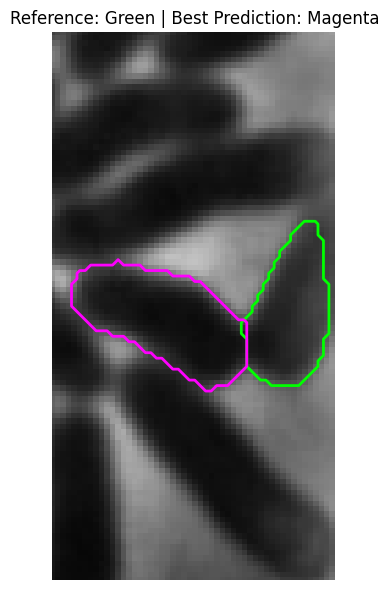

In [28]:
cell_id = 2231
reference_cell = dense_ref_a == cell_id

best_id = None
best_iou = 0.0

for pred_id in np.unique(original_599):
    if pred_id == 0:
        continue

    predicted_cell = original_599 == pred_id
    intersection = np.count_nonzero(reference_cell & predicted_cell)
    union = np.count_nonzero(reference_cell | predicted_cell)
    overlap = intersection / union

    if overlap > best_iou:
        best_id = int(pred_id)
        best_iou = overlap

print(f"Reference cell: {cell_id}")
print(f"Best-overlapping prediction: {best_id}")
print(f"Best IoU: {best_iou:.3f}")

# Visualize a crop around the reference cell.
raw_599 = tifffile.imread(data_dir / "01/t0599.tif")

rows, cols = np.where(reference_cell)
padding = 35

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(raw_599, cmap="gray")
ax.contour(
    reference_cell, levels=[0.5], colors=["lime"], linewidths=2
)

if best_id is not None:
    ax.contour(
        original_599 == best_id,
        levels=[0.5], colors=["magenta"], linewidths=2
    )

ax.set_xlim(max(0, cols.min() - padding),
            min(raw_599.shape[1], cols.max() + padding + 1))
ax.set_ylim(min(raw_599.shape[0], rows.max() + padding + 1),
            max(0, rows.min() - padding))
ax.set_title("Reference: Green | Best Prediction: Magenta")
ax.axis("off")
plt.tight_layout()
plt.show()

### Missed-Cell Analysis

Reference cell 2231 in frame 599 was unmatched before and after
area filtering. Its maximum IoU with any original prediction was
0.004. Visual inspection shows that the best-overlapping prediction
primarily covers a neighboring cell, consistent with a missed detection.

The tracking evaluation contains one additional missed edge when
using predicted masks. We next check whether this edge is associated
with cell 2231.

In [29]:
def edge_set(link_table):
    return set(
        link_table[
            ["source_reference_id", "target_reference_id"]
        ].itertuples(index=False, name=None)
    )


missed_with_reference = (
    dense_gt_edges - edge_set(dense_gt_mask_links)
)
missed_with_predictions = (
    dense_gt_edges - edge_set(dense_mapped_links)
)

additional_missed_edges = (
    missed_with_predictions - missed_with_reference
)

display(pd.DataFrame(
    sorted(additional_missed_edges),
    columns=["source_reference_id", "target_reference_id"],
))

,source_reference_id,target_reference_id
0,2231,2231


### Segmentation Error Propagation into Tracking

The additional missed edge was the continuation 2231 → 2231.
This edge was recovered using reference masks but missed using
Omnipose masks, where cell 2231 had no matching detection in frame 599.

This example demonstrates how a missed segmentation instance
propagates into a missing temporal link. On this transition, link
FN increased from 3 to 4, while division metrics remained unchanged.

### Impact on Division Counts

We compare predicted and reference division counts across the selected
validation transitions. False positive divisions inflate the count,
while missed divisions reduce it. Correct total counts can still hide
individual errors, so false positives and false negatives are also reported.

In [30]:
division_counts = validation_results[
    [
        "Transition", "Method", "Reference_divisions",
        "Division_TP", "Division_FP", "Division_FN"
    ]
].copy()

division_counts["Predicted_divisions"] = (
    division_counts["Division_TP"] + division_counts["Division_FP"]
)

division_counts["Count_error"] = (
    division_counts["Predicted_divisions"]
    - division_counts["Reference_divisions"]
)

display(division_counts)

,Transition,Method,Reference_divisions,Division_TP,Division_FP,Division_FN,Predicted_divisions,Count_error
0,0→1,Hungarian,0,0,0,0,0,0
1,0→1,Original division rules,0,0,0,0,0,0
2,0→1,Continuation protection,0,0,0,0,0,0
3,199→200,Hungarian,0,0,0,0,0,0
4,199→200,Original division rules,0,0,0,0,0,0
5,199→200,Continuation protection,0,0,0,0,0,0
6,399→400,Hungarian,3,0,0,3,0,-3
7,399→400,Original division rules,3,3,0,0,3,0
8,399→400,Continuation protection,3,3,0,0,3,0
9,599→600,Hungarian,7,0,0,7,0,-7


### Impact of Tracking Errors on Division Counts

Using ground-truth masks, the original division rules predicted 31
divisions for transition 798–799, compared with 17 reference events.
Continuation protection reduced the predicted count to 14, with
2 false positives and 5 missed divisions.

These results show that association errors can distort division counts
even without segmentation errors. Count error alone is insufficient:
false positives and false negatives can partially cancel each other.
The findings cover selected transitions, not the complete sequence.

In [31]:
division_counts.to_csv(
    results_dir / "division_count_errors_seq01.csv",
    index=False,
)

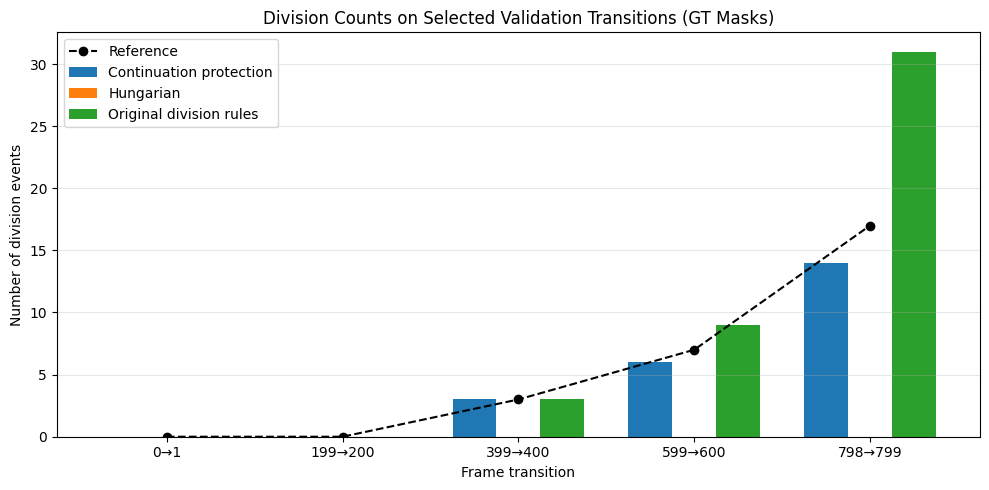

In [32]:
count_plot = division_counts.pivot(
    index="Transition",
    columns="Method",
    values="Predicted_divisions",
)

reference_counts = (
    division_counts.groupby("Transition")["Reference_divisions"]
    .first()
    .reindex(count_plot.index)
)

ax = count_plot.plot.bar(figsize=(10, 5), width=0.75)

ax.plot(
    range(len(count_plot)),
    reference_counts.values,
    color="black",
    marker="o",
    linestyle="--",
    label="Reference",
)

ax.set_xlabel("Frame transition")
ax.set_ylabel("Number of division events")
ax.set_title("Division Counts on Selected Validation Transitions (GT Masks)")
ax.tick_params(axis="x", rotation=0)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    results_dir / "division_counts_seq01.pdf",
    bbox_inches="tight",
)
plt.show()

### Progress Summary and Limitations

We established a pretrained Omnipose segmentation baseline and compared
three tracking methods: Hungarian assignment, division rules, and
division rules with continuation protection.

Across five selected transitions from sequence 01, using ground-truth
masks, continuation protection achieved a micro-averaged link F1 of
0.988 and division F1 of 0.800. The original division rules achieved
0.964 and 0.543, respectively.

We also evaluated tracking with Omnipose predictions on two transitions.
For transition 599–600, a missed segmentation instance caused one
additional missed temporal link. Division metrics remained unchanged.

These experiments evaluate frame-pair associations, not complete
trajectories. The results do not yet establish accurate inter-division
times or antibiotic effectiveness. Omnipose was used without fine-tuning;
the tracking methods are rule-based.

### Next Steps

- Evaluate consecutive transitions within a fixed temporal window.
- Connect frame-pair associations into tracks and visualize lineages.
- Measure accumulated tracking errors and missed division events.
- Investigate a learned association model after establishing the baseline.
- Keep sequence 04 untouched for final testing.

### Tracking Across Consecutive Frames

We evaluate Hungarian assignment and continuation protection over
50 consecutive transitions in sequence 01 (frames 40–90).

Ground-truth masks provide the detected objects. Tracking decisions
use geometry only; reference identities and lineage annotations are
used exclusively for evaluation. Predicted links are retained for
subsequent trajectory reconstruction.

In [33]:
window_sequence = "01"
window_start = 40
window_end = 90

window_lineage = pd.read_csv(
    data_dir / f"{window_sequence}_GT/TRA/man_track.txt",
    sep=r"\s+",
    header=None,
    names=["track_id", "start_frame", "end_frame", "parent_id"],
)

window_links = {}
window_records = []

mask_a = tifffile.imread(
    data_dir
    / f"{window_sequence}_GT/TRA/man_track{window_start:04d}.tif"
)

for frame in range(window_start, window_end):
    mask_b = tifffile.imread(
        data_dir
        / f"{window_sequence}_GT/TRA/man_track{frame + 1:04d}.tif"
    )

    reference_edges, reference_divisions = get_reference_events(
        mask_a, mask_b, frame, window_lineage
    )

    hungarian_links, _ = track_frame_pair(mask_a, mask_b)
    protected_links = track_with_protection(mask_a, mask_b)

    for method, links in [
        ("Hungarian", hungarian_links),
        ("Continuation protection", protected_links),
    ]:
        window_links[(frame, method)] = links.copy()

        predicted_divisions = extract_division_events(
            links.loc[links["event"] == "division"]
        )

        window_records.append({
            "Source_frame": frame,
            "Target_frame": frame + 1,
            "Method": method,
            "Reference_divisions": len(reference_divisions),
            **evaluate_links(links, reference_edges),
            **evaluate_divisions(
                predicted_divisions, reference_divisions
            ),
        })

    mask_a = mask_b

window_results = pd.DataFrame(window_records)

window_results.to_csv(
    results_dir / "tracking_seq01_frames0040_0090.csv",
    index=False,
)

print(f"Evaluated transitions per method: {window_end - window_start}")
display(window_results.head(10))

Evaluated transitions per method: 50


,Source_frame,Target_frame,Method,Reference_divisions,TP,FP,FN,Precision,Recall,Link_F1,Division_TP,Division_FP,Division_FN,Division_F1
0,40,41,Hungarian,0,3,0,0,1.0,1.00,1.000000,0,0,0,NaN
1,40,41,Continuation protection,0,3,0,0,1.0,1.00,1.000000,0,0,0,NaN
2,41,42,Hungarian,0,3,0,0,1.0,1.00,1.000000,0,0,0,NaN
3,41,42,Continuation protection,0,3,0,0,1.0,1.00,1.000000,0,0,0,NaN
4,42,43,Hungarian,0,3,0,0,1.0,1.00,1.000000,0,0,0,NaN
5,42,43,Continuation protection,0,3,0,0,1.0,1.00,1.000000,0,0,0,NaN
6,43,44,Hungarian,1,3,0,1,1.0,0.75,0.857143,0,0,1,0.0
7,43,44,Continuation protection,1,4,0,0,1.0,1.00,1.000000,1,0,0,1.0
8,44,45,Hungarian,0,4,0,0,1.0,1.00,1.000000,0,0,0,NaN
9,44,45,Continuation protection,0,4,0,0,1.0,1.00,1.000000,0,0,0,NaN


In [34]:
count_columns = [
    "TP", "FP", "FN",
    "Division_TP", "Division_FP", "Division_FN",
]

window_summary = (
    window_results.groupby("Method")[count_columns]
    .sum()
    .reset_index()
)

for prefix, output_column in [
    ("", "Link_F1"),
    ("Division_", "Division_F1"),
]:
    tp = window_summary[f"{prefix}TP"]
    fp = window_summary[f"{prefix}FP"]
    fn = window_summary[f"{prefix}FN"]

    denominator = 2 * tp + fp + fn
    window_summary[output_column] = (
        2 * tp / denominator.replace(0, np.nan)
    )

display(window_summary.round(3))

window_summary.to_csv(
    results_dir / "tracking_seq01_frames0040_0090_summary.csv",
    index=False,
)

,Method,TP,FP,FN,Division_TP,Division_FP,Division_FN,Link_F1,Division_F1
0,Continuation protection,197,0,0,1,0,0,1.000,1.0
1,Hungarian,196,0,1,0,0,1,0.997,0.0


### Track and Lineage Reconstruction

We assign independent track IDs by chaining predicted continuations.
At a predicted division, the parent track ends and two daughter tracks
begin. Mask labels identify objects within each frame; label equality
is not used to establish temporal identity.

In [35]:
track_records = {}
object_tracks = {}
next_track_id = 1


def create_track(frame, parent_track_id=0):
    global next_track_id

    track_id = next_track_id
    next_track_id += 1

    track_records[track_id] = {
        "track_id": track_id,
        "start_frame": frame,
        "end_frame": frame,
        "parent_track_id": parent_track_id,
    }
    return track_id


first_mask = tifffile.imread(
    data_dir
    / f"{window_sequence}_GT/TRA/man_track{window_start:04d}.tif"
)

for label in np.unique(first_mask):
    if label != 0:
        object_tracks[(window_start, int(label))] = create_track(
            window_start
        )

for frame in range(window_start, window_end):
    links = window_links[(frame, "Continuation protection")]

    target_mask = tifffile.imread(
        data_dir
        / f"{window_sequence}_GT/TRA/man_track{frame + 1:04d}.tif"
    )

    for link in links.itertuples(index=False):
        source_key = (frame, int(link.source_reference_id))
        target_key = (frame + 1, int(link.target_reference_id))
        parent_track = object_tracks[source_key]

        if link.event == "division":
            target_track = create_track(
                frame + 1,
                parent_track_id=parent_track,
            )
        else:
            target_track = parent_track
            track_records[target_track]["end_frame"] = frame + 1

        assert target_key not in object_tracks, "Conflicting target links."
        object_tracks[target_key] = target_track

    # Unlinked detections start new tracks.
    for label in np.unique(target_mask):
        if label == 0:
            continue

        key = (frame + 1, int(label))
        if key not in object_tracks:
            object_tracks[key] = create_track(frame + 1)

reconstructed_tracks = pd.DataFrame(track_records.values())

display(reconstructed_tracks)

reconstructed_tracks.to_csv(
    results_dir / "reconstructed_tracks_seq01_frames0040_0090.csv",
    index=False,
)

,track_id,start_frame,end_frame,parent_track_id
0,1,40,90,0
1,2,40,90,0
2,3,40,43,0
3,4,44,90,3
4,5,44,90,3


### Reconstructed Lineage Visualization

Horizontal segments show reconstructed tracks within frames 40–90.
Branches indicate predicted parent–daughter relationships.
Track endpoints at the observation boundaries do not imply cell birth
or death.

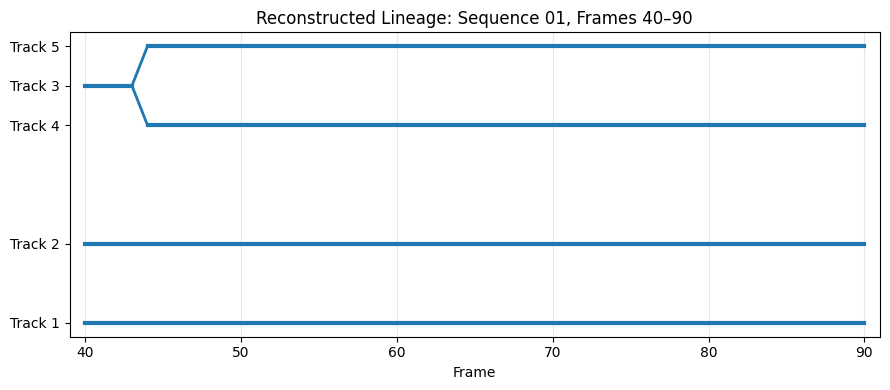

In [36]:
tracks = reconstructed_tracks.set_index("track_id")

# Place the parent between its two daughters.
track_positions = {1: 0, 2: 1, 3: 3, 4: 2.5, 5: 3.5}

fig, ax = plt.subplots(figsize=(9, 4))

for track_id, track in tracks.iterrows():
    y = track_positions[track_id]

    ax.plot(
        [track["start_frame"], track["end_frame"]],
        [y, y],
        linewidth=3,
        color="tab:blue",
    )

    parent_id = int(track["parent_track_id"])
    if parent_id != 0:
        parent = tracks.loc[parent_id]

        ax.plot(
            [parent["end_frame"], track["start_frame"]],
            [track_positions[parent_id], y],
            color="tab:blue",
            linewidth=2,
        )

ax.set_yticks(
    [track_positions[track_id] for track_id in tracks.index]
)
ax.set_yticklabels(
    [f"Track {track_id}" for track_id in tracks.index]
)
ax.set_xlabel("Frame")
ax.set_title("Reconstructed Lineage: Sequence 01, Frames 40–90")
ax.set_xlim(39, 91)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(
    results_dir / "lineage_seq01_frames0040_0090.pdf",
    bbox_inches="tight",
)
plt.show()

### Evaluation in a Dense Temporal Window

We evaluate 20 consecutive transitions spanning frames 590–610 of
sequence 01 using ground-truth masks and unchanged tracking parameters.
This extends the sparse-window experiment to a more crowded setting.
The window includes the previously inspected transition 599–600,
so it is an extended validation experiment, not an independent test.

In [ ]:
dense_window_records = []
dense_window_links = {}

mask_a = tifffile.imread(
    data_dir / "01_GT/TRA/man_track0590.tif"
)

for frame in range(590, 610):
    mask_b = tifffile.imread(
        data_dir / f"01_GT/TRA/man_track{frame + 1:04d}.tif"
    )

    reference_edges, reference_divisions = get_reference_events(
        mask_a, mask_b, frame, window_lineage
    )

    hungarian_links, _ = track_frame_pair(mask_a, mask_b)
    protected_links = track_with_protection(mask_a, mask_b)

    for method, links in [
        ("Hungarian", hungarian_links),
        ("Continuation protection", protected_links),
    ]:
        dense_window_links[(frame, method)] = links.copy()

        predicted_divisions = extract_division_events(
            links.loc[links["event"] == "division"]
        )

        dense_window_records.append({
            "Source_frame": frame,
            "Target_frame": frame + 1,
            "Method": method,
            "Reference_divisions": len(reference_divisions),
            **evaluate_links(links, reference_edges),
            **evaluate_divisions(
                predicted_divisions, reference_divisions
            ),
        })

    mask_a = mask_b

dense_window_results = pd.DataFrame(dense_window_records)

dense_window_summary = (
    dense_window_results.groupby("Method")[
        ["TP", "FP", "FN", "Division_TP", "Division_FP", "Division_FN"]
    ]
    .sum()
    .reset_index()
)

for prefix, metric in [
    ("", "Link_F1"),
    ("Division_", "Division_F1"),
]:
    tp = dense_window_summary[f"{prefix}TP"]
    fp = dense_window_summary[f"{prefix}FP"]
    fn = dense_window_summary[f"{prefix}FN"]

    dense_window_summary[metric] = (
        2 * tp / (2 * tp + fp + fn).replace(0, np.nan)
    )

dense_window_results.to_csv(
    results_dir / "tracking_seq01_frames0590_0610.csv",
    index=False,
)
dense_window_summary.to_csv(
    results_dir / "tracking_seq01_frames0590_0610_summary.csv",
    index=False,
)

display(dense_window_summary.round(3))